In [2]:
import geopandas as gpd
import sys
sys.path.append("../Functions")

%load_ext autoreload
%autoreload 2

from GSC_funcs import *

In [3]:
fp = gpd.read_file("../Data/selected_perimeters.gpkg")

In [4]:
aoi_bb = [-8.38, 39.78, -7.72, 40.2]

# Here we can select which bands we are interested in using.
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    'swir16',  # band 6, shortwave infrared 1
    'swir22',  # band 7, shortwave infrared 2
]

catalog = connect_MPC()

In [13]:
from datetime import datetime, timedelta

start_date = datetime(2017, 4, 1)
end_date = datetime(2018, 5, 1)
period = 7 # in days

date_ranges_A = date_ranges(start_date, end_date, period)
print(date_ranges_A)

['2017-04-02/2017-04-08', '2017-04-09/2017-04-15', '2017-04-16/2017-04-22', '2017-04-23/2017-04-29', '2017-04-30/2017-05-06', '2017-05-07/2017-05-13', '2017-05-14/2017-05-20', '2017-05-21/2017-05-27', '2017-05-28/2017-06-03', '2017-06-04/2017-06-10', '2017-06-11/2017-06-17', '2017-06-18/2017-06-24', '2017-06-25/2017-07-01', '2017-07-02/2017-07-08', '2017-07-09/2017-07-15', '2017-07-16/2017-07-22', '2017-07-23/2017-07-29', '2017-07-30/2017-08-05', '2017-08-06/2017-08-12', '2017-08-13/2017-08-19', '2017-08-20/2017-08-26', '2017-08-27/2017-09-02', '2017-09-03/2017-09-09', '2017-09-10/2017-09-16', '2017-09-17/2017-09-23', '2017-09-24/2017-09-30', '2017-10-01/2017-10-07', '2017-10-08/2017-10-14', '2017-10-15/2017-10-21', '2017-10-22/2017-10-28', '2017-10-29/2017-11-04', '2017-11-05/2017-11-11', '2017-11-12/2017-11-18', '2017-11-19/2017-11-25', '2017-11-26/2017-12-02', '2017-12-03/2017-12-09', '2017-12-10/2017-12-16', '2017-12-17/2017-12-23', '2017-12-24/2017-12-30', '2017-12-31/2018-01-06',

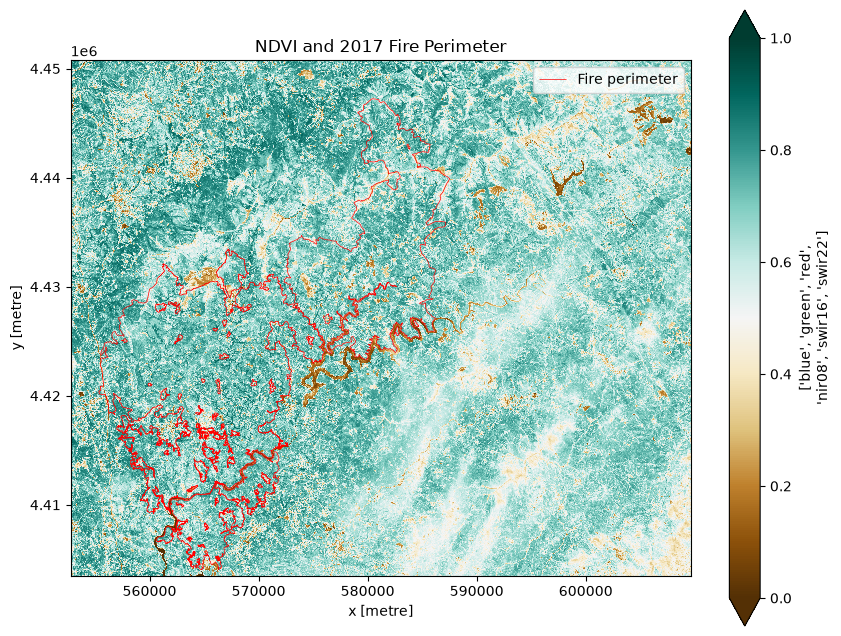

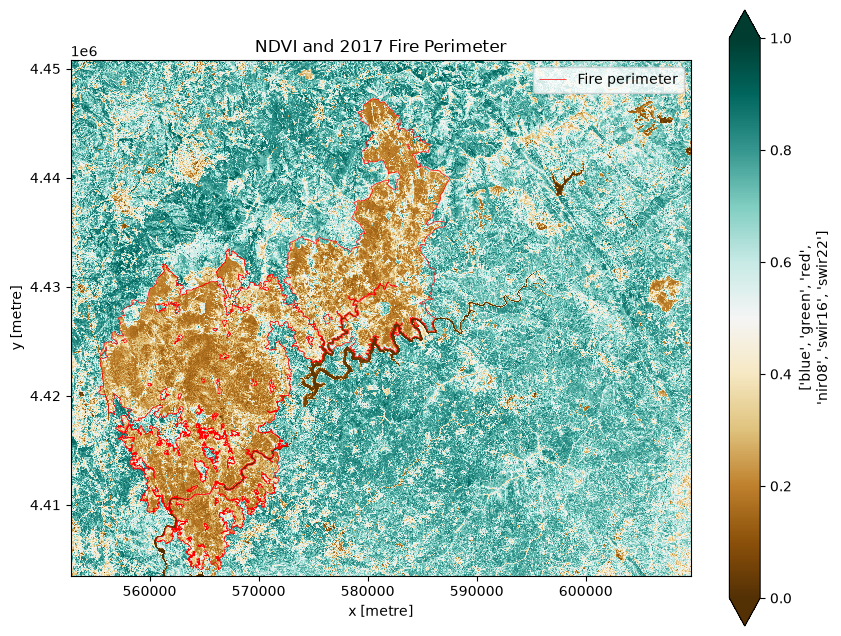

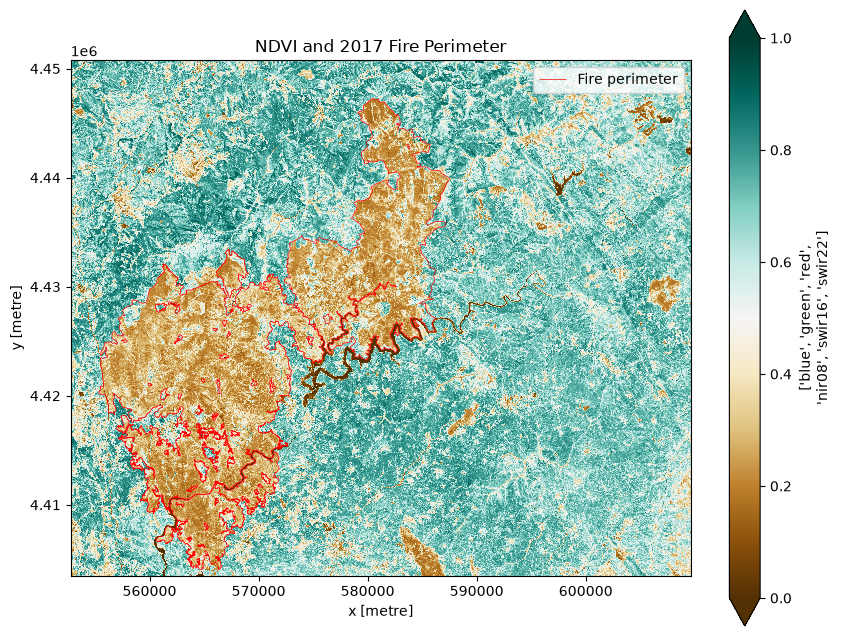

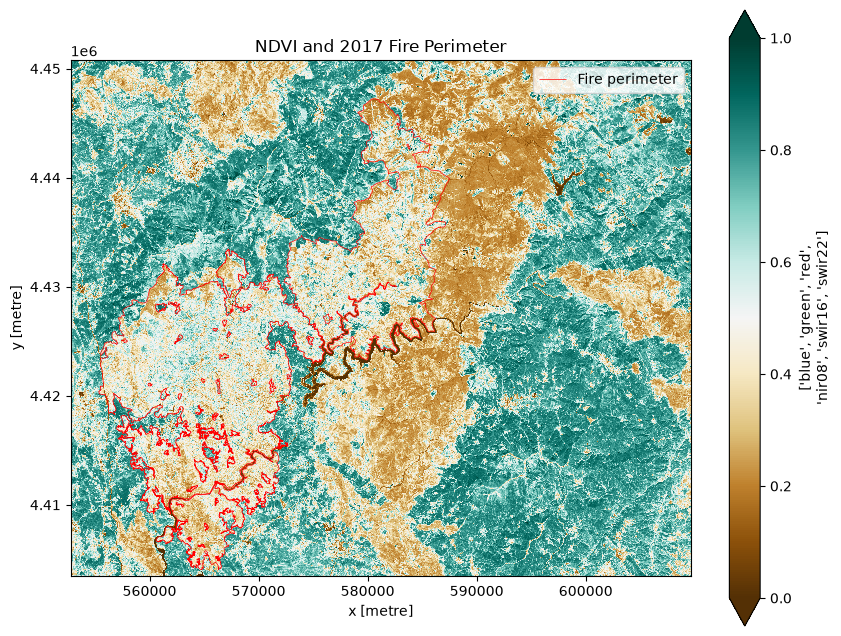

In [15]:
#rngs = len(date_ranges_A)
#prop = 0
ndvis = []
for rng in date_ranges_A:
    items = search_Landsat(aoi_bb, rng, 10, catalog)
    if len(items) != 0:
        filtered_items = filter_items(aoi_bb, items, 0.7)
        if len(filtered_items) != 0:
            ds = load_scene(filtered_items[0], bands, aoi_bb)
            # Calculate NDVI
            normalised_index = ndvi(ds)
            ndvis.append(normalised_index)
            
            # Create figure and axes
            fig, ax = plt.subplots(figsize=(10, 8))
            
            # Plot NDVI
            normalised_index.plot.imshow(
                ax=ax,
                cmap="BrBG",
                robust=True,
                vmin=0,
                vmax=1,
                add_colorbar=True
            )
            
            # Reproject fire perimeter to match Landsat CRS
            fp_landsat = fp.to_crs(ds.rio.crs)
            
            # Overlay perimeter
            fp_landsat.boundary.plot(
                ax=ax,
                color="red",
                linewidth=0.5,
                label="Fire perimeter"
            )
            
            ax.set_title("NDVI and 2017 Fire Perimeter")
            ax.legend()
            
            plt.show()
            
    #prop = prop + 1
    #print(str(round((prop/rngs)*100))+"%")

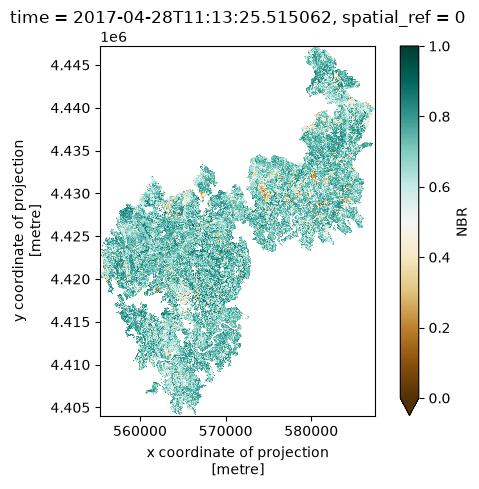

In [23]:
fp = fp.to_crs(ndvis[0].rio.crs)

ndvi_clipped = ndvis[0].rio.clip(fp.geometry)

vmin, vmax = 0, 1

fig, ax = plt.subplots()
ndvi_clipped.plot.imshow(vmin=vmin, vmax=vmax, cmap="BrBG", cbar_kwargs={"label": "NBR"})
ax.set_aspect('equal')